# 01 — A tiny character-level Transformer

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/brains-to-models/blob/main/code/notebooks/01_tiny_transformer.ipynb)

## Why this notebook

A language model takes a prefix and assigns probabilities to possible continuations. This can sound simple until the representation, attention operation, objective and sampling rule are all hidden behind an API. Here they are small enough to inspect. A one-layer, four-head character-level Transformer learns from a designed corpus, and every parameter update is implemented in NumPy.

The notebook lets you connect a loss curve to an actual prediction problem. You will see repeated sentence types, count the vocabulary, inspect a causal attention map and generate a continuation. These observations support claims about this calculation. They do not by themselves settle how much a larger model understands, or whether next-token prediction is its only training stage.

### Learning goals

1. Explain the difference between a token, an embedding, an attention weight and an output probability.
2. Read a causal attention matrix without mistaking it for a map of meaning.
3. Interpret negative log-likelihood relative to a simple baseline.
4. Distinguish fitting a repeated corpus from generalizing to new language or tasks.

**Starting knowledge.** You need only basic vectors and the idea of a probability. The mathematical reading below introduces the notation. The training run uses a CPU; no pretrained model, GPU, API key or text download is needed.

Section numbers in the background readings refer to the [August background paper](https://github.com/arvidl/brains-to-models/blob/main/paper/background/august-perspective.pdf). For the current paper and 30-minute presentation, use the [paper](https://github.com/arvidl/brains-to-models/blob/main/paper/main.pdf) and the [slide-to-resource guide](https://github.com/arvidl/brains-to-models/blob/main/talk/resources.md).


## Concepts and two reading paths

<details open>
<summary><strong>For clinicians and neuroscientists</strong></summary>

**Token and vocabulary.** A token is one unit of the input. Here it is a character; the vocabulary is the set of characters actually present in the corpus. Many larger language models use subword units. The printed vocabulary below is the authority for this run: do not assume that every letter occurs.

**Embedding and position.** Each character is assigned a learned vector. A position vector supplies its place in the sequence. Nearby embedding vectors need not have a human-interpretable meaning, especially in a tiny model with limited training data.

**Attention.** At each position, a query is compared with earlier keys. Normalized scores determine how value vectors are combined. The causal mask prevents a position from using future characters during prediction. An attention head is one such computation, rather than a separate human-like faculty.

**Training versus generation.** During training, the next character is known and is used to calculate an error. During generation, the model samples a character from its predicted distribution and adds it to the prefix. An improbable sample can change the subsequent context. Temperature changes this sampling distribution without retraining the weights.

Follow the corpus, the learning curve and the generated sentence first. Then ask what experiment would distinguish learning useful regularities from reproducing recurring templates.

</details>

<details>
<summary><strong>For mathematically inclined readers</strong></summary>

For a sequence $x_1,\ldots,x_T$, the autoregressive factorization is

$$p_\theta(x_{1:T})=\prod_{t=1}^{T}p_\theta(x_t\mid x_{<t}).$$

The mean training objective is negative log-likelihood,

$$\mathcal L(\theta)=-\frac1N\sum_t\log p_\theta(x_{t+1}\mid x_{\le t}).$$

A uniform predictor over $|\mathcal V|$ tokens has loss $\log|\mathcal V|$ nats. A smaller loss indicates better probability assigned to the observed targets on the measured data. Training loss alone establishes neither held-out calibration nor understanding.

One head computes

$$A=\operatorname{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}+M\right),\qquad Z=AV,$$

where rows of $A$ sum to one and $M_{ij}=-\infty$ for future positions $j>i$. Multiple heads, residual paths, normalization, a feed-forward block and an output projection complete this small architecture. Backpropagation updates embeddings, projections and other trainable parameters; the experiment is not a fixed-feature readout.

</details>


### Run in Colab or locally

Click **Open in Colab**, connect to a standard **CPU** runtime, and run the setup cell followed by the remaining cells in order (**Runtime → Run all**). The setup downloads the shared code and figure references from the public repository, installs the small numerical dependencies, and prints the checkout and Python version. It excludes the large presentation. No GPU, API key, patient data or Google Drive mount is needed.

Locally, use the environment in the [repository instructions](https://github.com/arvidl/brains-to-models/blob/main/README.md#run-the-notebooks) and select its Python kernel in Cursor or JupyterLab. The setup finds the repository and sets the working directory to `code/notebooks`, so exercise paths such as `%load ../solutions/...py` work in either environment.

Re-running setup reuses the existing checkout; it does not discard your runtime edits or pull new code automatically. For a fresh Colab checkout after repository updates, use **Runtime → Disconnect and delete runtime**, then reconnect and run again. Use **File → Save a copy in Drive** to retain notebook edits, and download generated files separately before the runtime ends. Saved output is a preview; rerunning produces the evidence for your session.


In [1]:
# Locate the shared code locally, or download a small checkout in Colab.
import os
from pathlib import Path
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
REPO_URL = os.environ.get("BRAINSMODELS_REPO_URL",
                          "https://github.com/arvidl/brains-to-models.git")
if IN_COLAB:
    root = Path(os.environ.get("BRAINSMODELS_COLAB_ROOT",
                               "/content/brains-to-models"))
    if not (root / "code/src/brainsmodels").is_dir():
        # Sparse checkout keeps the large presentation out of the runtime.
        subprocess.check_call(["git", "clone", "--depth", "1", "--filter=blob:none",
                               "--sparse", "--branch", "main", REPO_URL, str(root)])
        subprocess.check_call(["git", "-C", str(root), "sparse-checkout", "set",
                               "code", "paper/figures"])
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q",
                           "numpy>=1.26", "matplotlib>=3.8"])
else:
    here = Path.cwd().resolve()
    root = next((p for p in (here, *here.parents)
                 if (p / "pyproject.toml").is_file()
                 and (p / "code/src/brainsmodels").is_dir()), None)
    if root is None:
        raise RuntimeError("Open this notebook inside a brains-to-models checkout, "
                           "or use its Open in Colab badge.")

src = str(root / "code/src")
if src not in sys.path:
    sys.path.insert(0, src)
# Keep relative exercise paths consistent in Colab, JupyterLab and Cursor.
os.chdir(root / "code/notebooks")
repo = ROOT = root
import json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
print("Checkout:", root)
print("Python:", sys.version.split()[0], "| NumPy:", np.__version__)
# End of shared setup.

from brainsmodels.repro import DEFAULT_SEED, set_seed
from brainsmodels.tiny_transformer import (
    CharTokenizer,
    TinyTransformer,
    make_corpus,
    render_paper_figure,
    write_figure,
)

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})
print("repo root:", root)
print("seed:", SEED)

Checkout: CHECKOUT
Python: 3.12.2 | NumPy: 2.5.2
repo root: CHECKOUT
seed: 7


## A small designed corpus

The corpus combines five sentence frames. Inspect their frequencies before training. Familiar-looking output can result from learning these regularities; evaluate new text separately before claiming generalization.

**Before running.** Count unique sentence types as well as characters. The list makes the restricted training distribution visible before fitting. Ask which continuations can be predicted from frequent local fragments and which would require a novel combination. The five diverse windows are chosen examples of string variation, not evidence that the dataset spans natural language.


In [2]:
from collections import Counter

text = make_corpus(seed=SEED)
tokenizer = CharTokenizer.from_text(text)
print(f"{len(text)} characters, vocab {tokenizer.vocab_size}: {tokenizer.chars!r}")

sentences = [s.strip() + "." for s in text.split(".") if s.strip()]
types = Counter(sentences)
print(f"{len(sentences)} sentences, but only {len(types)} unique types:\n")
for sent, n in types.most_common():
    print(f"  {n:3d}×  {sent}")

# Consecutive pairs are the smallest windows that still vary. Distance is
# 1 − SequenceMatcher ratio (order-aware; a repeated sentence is close to
# itself). Seed with the two farthest windows, then greedily add the one
# that maximises its min-distance to those already chosen.
from difflib import SequenceMatcher

windows = list(dict.fromkeys(
    f"{sentences[i]} {sentences[i + 1]}" for i in range(len(sentences) - 1)
))


def seq_dist(a: str, b: str) -> float:
    return 1.0 - SequenceMatcher(None, a, b).ratio()


slen = 5
best_d, seed_i, seed_j = -1.0, 0, 1
for i, a in enumerate(windows):
    for j, b in enumerate(windows[i + 1 :], start=i + 1):
        d = seq_dist(a, b)
        if d > best_d:
            best_d, seed_i, seed_j = d, i, j

selected = [windows[seed_i], windows[seed_j]]
remaining = [w for w in windows if w not in selected]
while remaining and len(selected) < slen:
    best = max(remaining, key=lambda w: min(seq_dist(w, s) for s in selected))
    selected.append(best)
    remaining.remove(best)

print(
    f"\n{len(selected)} most different two-sentence windows "
    f"(greedy max-min sequence distance; first two are the farthest pair):\n"
)
for i, window in enumerate(selected, 1):
    print(f"{i:3d}  {window}")


15744 characters, vocab 27: [' ', '.', ':', '?', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'w', 'x', 'y']
400 sentences, but only 79 unique types:

   15×  the fox sat on the box.
   12×  q: where did the fox sit? a: on the hat.
   10×  according to wikipedia the dog sat on the log.
    9×  once upon a time the dog sat on the box.
    9×  according to wikipedia the dog sat on the box.
    9×  the fox sat on the log.
    9×  once upon a time the cat sat on the mat.
    9×  according to wikipedia the cat sat on the mat.
    9×  according to wikipedia the fox sat on the hat.
    8×  the fox sat on the mat.
    8×  according to wikipedia the dog sat on the hat.
    8×  once upon a time the fox sat on the mat.
    7×  q: where did the cat sit? a: on the log.
    7×  according to wikipedia the fox sat on the log.
    7×  the dog sat on the hat.
    7×  the dog sat on the log.
    7×  q: where did the dog sit? a: on the box.
    7×  th


5 most different two-sentence windows (greedy max-min sequence distance; first two are the farthest pair):

  1  q: where did the cat sit? a: on the hat. q: where did the fox sit? a: on the mat.
  2  the dog sat on the mat. according to wikipedia the cat sat on the box.
  3  the cat sat on the mat. breaking from tokyo: the dog sat on the log.
  4  once upon a time the fox sat on the log. breaking from paris: the fox sat on the mat.
  5  q: where did the fox sit? a: on the box. once upon a time the fox sat on the hat.


## One layer, four heads, next-character loss

Token + position embeddings, causal multi-head attention, a small ReLU FFN, then a linear readout. The training objective is next-character negative log-likelihood — predict what comes next.

**Before running.** Training updates parameters to reduce the loss on sampled windows. Generation then uses those fitted parameters without updating them. Predict whether changing `temperature` should alter the training history; it should not. To compare two training runs, fix the corpus and initialization or explicitly report their changes. The generated continuation below is one sample, so do not use its fluency as the only evaluation.


In [3]:
model = TinyTransformer(vocab_size=tokenizer.vocab_size, seed=SEED)
history = model.train(tokenizer.encode(text), n_steps=500, seed=SEED)

print(model.generate("the cat sat on the ", tokenizer, n_tokens=50, temperature=0.6, seed=SEED))

step 0001/500  loss 3.2955


step 0050/500  loss 2.2944


step 0100/500  loss 1.4806


step 0150/500  loss 1.1291


step 0200/500  loss 0.8082


...

step 0300/500  loss 0.3894


step 0350/500  loss 0.3334


step 0400/500  loss 0.2847


step 0450/500  loss 0.2937


step 0500/500  loss 0.2428
the cat sat on the log. og once upon a time the dog sat on the log. o


## Model figure

Inspect the causal attention mask, training cross-entropy and generated text. Attention weights show one operation in this model; they do not by themselves explain the output or identify a human attentional mechanism.

**Before running.** Identify the query-position and key-position axes in an attention panel. Future positions should be masked. Then compare the training curve with the object-initial readout: the former averages prediction error across training windows, while the latter probes selected continuations. A falling aggregate objective need not make every selected probability move monotonically.


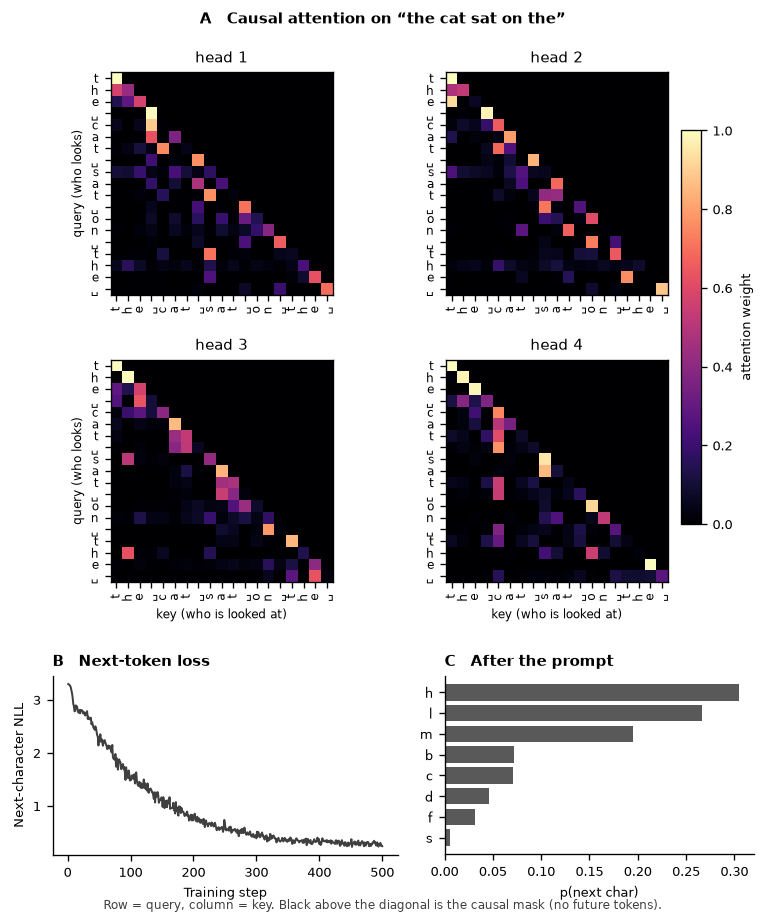

wrote CHECKOUT/paper/figures/tiny_transformer_attention.pdf
wrote CHECKOUT/paper/figures/tiny_transformer_attention.png
wrote CHECKOUT/paper/figures/tiny_transformer_attention.pdf


In [4]:
fig = render_paper_figure(model, tokenizer, history)
plt.show()

out = write_figure(model, tokenizer, history, root / "paper" / "figures")
print("wrote", out)

## Read the result before drawing a wider conclusion

The sentence counter matters as much as the loss curve. Hundreds of strings need not provide hundreds of independent linguistic constructions. Repeated templates make next-character prediction easier and let you inspect a compact mechanism, but they also make memorization a plausible explanation for fluent continuations. The sequence-distance examples illustrate variation among windows; they are not a train/test split or an estimate of semantic diversity.

In the figure, read the loss axis and attention axes explicitly. A dark attention cell reports a normalized routing weight for one head and input position. It does not report that character's full causal contribution to the final output. Values, other heads and residual paths also matter. Notebook 10 gives an exact two-key counterexample, and notebook 08 compares weights, derivatives and finite replacements in a common model.

### A useful intervention sequence

First keep the trained model and prefix fixed and vary generation temperature. This changes sampling, not learning. Next change the prefix while keeping temperature and random seed fixed. Finally retrain with a changed corpus while holding the architecture and training budget fixed. These interventions answer different questions; changing all three at once makes the cause of a difference difficult to identify.

The exercises compare masking and alternative prediction rules. If you evaluate generalization, choose a split before fitting any model, train all competitors on the same training partition and reserve the evaluation text. A baseline trained on less data is not an equal-data comparison. Repeating the same sentence templates in both partitions also leaves a weaker test than holding out a construction or combination entirely.

### Biological and clinical interpretation

The model demonstrates how sequential prediction can be implemented without a biological nervous system. It does not show that brains use this implementation, nor that prediction alone explains language. Conversely, a small model's limited behavior does not establish the limits of larger systems. A clinically useful language system would require task-specific evaluation of factual accuracy, calibration, failures and consequences, none of which is measured by this designed corpus.

**Check your understanding.** If training loss falls but two generated samples differ, there is no contradiction: a distribution can improve while samples remain variable. If removing the causal mask reduces loss, ask whether future information has leaked into the prediction task before calling it an improvement. Describe which prefix information would actually be available at generation time.


### Exercises

1. **Drop the causal mask.** The black upper triangle in panel A is not decoration: position $t$ is forbidden from seeing $t{+}1,t{+}2,\ldots$. Recompute the attention weights from the trained $Q$ and $K$ *without* that mask. How much mass does a mid-prompt query put on characters that have not been written yet? What would go wrong at generation time if the model had been allowed to learn that look-ahead?

<!-- solution-box: 01_1_drop_the_causal_mask.py -->
<details>
<summary><strong>Show solution</strong> — Drop the causal mask</summary>

Takes seconds on a laptop. Copy the block below into a new cell. From a clone of the repository, `%load ../solutions/01_1_drop_the_causal_mask.py` inserts the same code together with the few lines of setup it needs to run outside the notebook.

```python
"""Standalone solution; also %load-able from the companion notebook."""
from __future__ import annotations

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

try:
    _SRC = Path(__file__).resolve().parents[1] / "src"
except NameError:
    _cwd = Path.cwd().resolve()
    if (_cwd / "src" / "brainsmodels").is_dir():
        _SRC = _cwd / "src"
    elif (_cwd.parent / "src" / "brainsmodels").is_dir():
        _SRC = _cwd.parent / "src"
    else:
        _SRC = _cwd / "code" / "src"
if str(_SRC) not in sys.path:
    sys.path.insert(0, str(_SRC))

from brainsmodels.repro import DEFAULT_SEED, set_seed

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

from brainsmodels.tiny_transformer import _softmax, train_demo
model, tokenizer, text, _ = train_demo(seed=SEED, n_steps=200)
prompt = "the cat sat on the "
ids = tokenizer.encode(prompt)
logits, causal = model.forward(ids, record_attn=True)
q, k = model._cache["q"], model._cache["k"]
scale = np.sqrt(model._d_head)
scores = np.einsum("bhtd,bhsd->bhts", q, k) / scale
leaky = _softmax(scores, axis=-1)

t = len(prompt)
# Query at the space after "cat" (index of that space).
q_at = prompt.index(" ", 4)
future = slice(q_at + 1, t)
leaked = float(leaky[0, :, q_at, future].sum() / model.n_heads)
blocked = float(causal[0, :, q_at, future].sum() / model.n_heads)
print(f"query at index {q_at} ({prompt[q_at]!r})")
print(f"mean mass on later characters, causal mask on : {blocked:.3f}")
print(f"mean mass on later characters, mask dropped   : {leaked:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(8.2, 3.4))
labels = [("␣" if c == " " else c) for c in prompt]
for ax, mat, title in (
    (axes[0], causal[0, 0, :t, :t], "head 1, causal"),
    (axes[1], leaky[0, 0, :t, :t], "head 1, no mask"),
):
    ax.imshow(mat, cmap="magma", vmin=0, vmax=max(0.2, float(mat.max())))
    ax.set_xticks(range(t), labels, rotation=90, fontsize=7)
    ax.set_yticks(range(t), labels, fontsize=7)
    ax.set_title(title, fontsize=9)
fig.suptitle("Without the mask, a query can look at characters that do not yet exist")
plt.tight_layout()
plt.show()
print('Removing the mask exposes future characters during training. Left-to-right generation has no such observations, so this changes the prediction task and leaks the target.')
```

</details>
<!-- /solution-box -->


2. **Compare context baselines.** Fit unigram, bigram and Transformer models on the same training partition. Compare next-character negative log likelihood on held-out windows. How much does each additional source of context help on this corpus?

<!-- solution-box: 01_2_a_unigram_is_not_enough.py -->
<details>
<summary><strong>Show solution</strong> — Compare context baselines</summary>

Takes seconds on a laptop. Copy the block below into a new cell. From a clone of the repository, `%load ../solutions/01_2_a_unigram_is_not_enough.py` inserts the same code together with the few lines of setup it needs to run outside the notebook.

```python
"""Standalone solution; also %load-able from the companion notebook."""
from __future__ import annotations

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

try:
    _SRC = Path(__file__).resolve().parents[1] / "src"
except NameError:
    _cwd = Path.cwd().resolve()
    if (_cwd / "src" / "brainsmodels").is_dir():
        _SRC = _cwd / "src"
    elif (_cwd.parent / "src" / "brainsmodels").is_dir():
        _SRC = _cwd.parent / "src"
    else:
        _SRC = _cwd / "code" / "src"
if str(_SRC) not in sys.path:
    sys.path.insert(0, str(_SRC))

from brainsmodels.repro import DEFAULT_SEED, set_seed

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

from brainsmodels.tiny_transformer import CharTokenizer, make_corpus, train_demo
text = make_corpus(seed=SEED)
tokenizer = CharTokenizer.from_text(text)
ids = tokenizer.encode(text)
n = len(ids)
cut = int(0.85 * n)
train_ids, test_ids = ids[:cut], ids[cut:]
from brainsmodels.tiny_transformer import TinyTransformer
model = TinyTransformer(tokenizer.vocab_size, seed=SEED)
model.train(train_ids, n_steps=200, seed=SEED)

unigram = np.ones(tokenizer.vocab_size)
for i in train_ids:
    unigram[int(i)] += 1.0
unigram = unigram / unigram.sum()

bigram = np.ones((tokenizer.vocab_size, tokenizer.vocab_size))
for a, b in zip(train_ids[:-1], train_ids[1:]):
    bigram[int(a), int(b)] += 1.0
bigram = bigram / bigram.sum(axis=1, keepdims=True)

def nll_unigram(seq):
    return float(-np.mean(np.log(unigram[seq])))

def nll_bigram(seq):
    return float(-np.mean(np.log(bigram[seq[:-1], seq[1:]])))

def nll_model(seq, block=32):
    losses = []
    for start in range(0, len(seq) - block - 1, block):
        ctx = seq[start : start + block]
        tgt = seq[start + 1 : start + 1 + block]
        logits, _ = model.forward(ctx)
        p = np.exp(logits[0] - logits[0].max(axis=-1, keepdims=True))
        p = p / p.sum(axis=-1, keepdims=True)
        losses.append(-np.log(np.clip(p[np.arange(block), tgt], 1e-9, 1.0)).mean())
    return float(np.mean(losses))

print(f"chance (ln V)   {np.log(tokenizer.vocab_size):.3f}")
print(f"unigram  test   {nll_unigram(test_ids):.3f}")
print(f"bigram   test   {nll_bigram(test_ids):.3f}")
print(f"1-layer  test   {nll_model(test_ids):.3f}")
print('Compare the measured held-out losses. Unigram, bigram and Transformer models use different amounts of context; these results concern prediction on this designed corpus.')
```

</details>
<!-- /solution-box -->


3. **Temperature and sampling.** Sample 20 continuations of `the cat sat on the ` at temperatures 0, 0.4 and 1.2. Compare repetition, word variety and invalid spellings. What does this measure, and what evidence would be needed to assess factual reliability?

<!-- solution-box: 01_3_temperature_is_not_a_belief.py -->
<details>
<summary><strong>Show solution</strong> — Temperature and sampling</summary>

Takes seconds on a laptop. Copy the block below into a new cell. From a clone of the repository, `%load ../solutions/01_3_temperature_is_not_a_belief.py` inserts the same code together with the few lines of setup it needs to run outside the notebook.

```python
"""Standalone solution; also %load-able from the companion notebook."""
from __future__ import annotations

from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np

try:
    _SRC = Path(__file__).resolve().parents[1] / "src"
except NameError:
    _cwd = Path.cwd().resolve()
    if (_cwd / "src" / "brainsmodels").is_dir():
        _SRC = _cwd / "src"
    elif (_cwd.parent / "src" / "brainsmodels").is_dir():
        _SRC = _cwd.parent / "src"
    else:
        _SRC = _cwd / "code" / "src"
if str(_SRC) not in sys.path:
    sys.path.insert(0, str(_SRC))

from brainsmodels.repro import DEFAULT_SEED, set_seed

SEED = set_seed(DEFAULT_SEED)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

from brainsmodels.tiny_transformer import train_demo
model, tokenizer, _, _ = train_demo(seed=SEED, n_steps=400)
prompt = "the cat sat on the "
temps = (0.0, 0.4, 1.2)
objects = ("mat", "hat", "log", "box")

for T in temps:
    texts = [
        model.generate(prompt, tokenizer, n_tokens=12, temperature=T, seed=SEED + k)
        for k in range(20)
    ]
    tails = [t[len(prompt) :].split()[0] if t[len(prompt) :].split() else "" for t in texts]
    hits = {w: sum(w in tail for tail in tails) for w in objects}
    uniq = len(set(tails))
    print(f"T={T:<4}  unique first-words {uniq:2d}  object hits {hits}")
    print("   e.g.", texts[0][len(prompt) : 28])

print('Temperature rescales the next-character distribution. Compare repetition and variation in the samples; sampling sharpness alone does not measure factual accuracy or understanding.')
```

</details>
<!-- /solution-box -->


### Questions for reflection

Use these questions to distinguish what the calculation shows from the assumptions and interpretations attached to it. Write an answer before consulting the instructor notes.


1. What does next-character prediction measure in this experiment?

2. Why is the causal mask necessary for left-to-right prediction?

3. How would you compare this Transformer fairly with a unigram or bigram model?

4. Does a concentrated output distribution imply a calibrated belief?

5. What would be needed to interpret a head as a functional component?


### Further reading

These references provide background for the models and discussion. Distinguish primary experiments, reviews and commentary when using them as evidence. Section references follow the August background paper.

1. **Vaswani, A., et al. (2017).** [*Attention Is All You Need*](https://arxiv.org/abs/1706.03762). *NeurIPS* 30. arXiv:1706.03762.
2. **Brown, T. B., et al. (2020).** [*Language Models are Few-Shot Learners*](https://arxiv.org/abs/2005.14165). *NeurIPS* 33. arXiv:2005.14165.
3. **Bommasani, R., et al. (2021).** [*On the Opportunities and Risks of Foundation Models*](https://arxiv.org/abs/2108.07258). arXiv:2108.07258.
4. **Elhage, N., et al. (2021).** [*A Mathematical Framework for Transformer Circuits*](https://transformer-circuits.pub/2021/framework/index.html). *Transformer Circuits Thread*.
5. **Jain, S., and Wallace, B. C. (2019).** [*Attention is not Explanation*](https://aclanthology.org/N19-1357/). *NAACL* 2019, 3543–3556.
6. **Schrimpf, M., et al. (2021).** [*The neural architecture of language: Integrative modeling converges on predictive processing*](https://www.pnas.org/doi/10.1073/pnas.2105646118). *PNAS* 118(45), e2105646118.
7. **Goldstein, A., et al. (2022).** [*Shared computational principles for language processing in humans and deep language models*](https://doi.org/10.1038/s41593-022-01026-4). *Nature Neuroscience* 25, 369–380.
8. **Lindsey, J., Gurnee, W., Ameisen, E., et al. (2025).** [*On the Biology of a Large Language Model*](https://transformer-circuits.pub/2025/attribution-graphs/biology.html). *Transformer Circuits Thread*.
9. **Ouyang, L., et al. (2022).** [*Training language models to follow instructions with human feedback*](https://arxiv.org/abs/2203.02155). *NeurIPS* 35. arXiv:2203.02155.
